# 27 · Final error analysis (descriptive)

## Purpose

This notebook describes **where** the final model makes its errors on the test set. It does **not** try to improve the
model:

- no new model, no tuning, no new feature, no threshold change, no row removed;
- the final model (frozen in notebook 25, evaluated once in notebook 26) is refitted exactly as in notebook 26, and its
  test predictions are reproduced;
- nothing found here is used to change the model. Every weakness is recorded as an **observation / limitation**.

**Which data is which:**

| Data | Role here |
|---|---|
| **Training set** (16,219 listings) | used only to fit the frozen pipeline, exactly as in notebook 26. Also used to say whether a test listing's locality was frequent, rare or unseen **in the training data** |
| **Cross-validation** (notebook 25) | not re-run. Its numbers are quoted only for context |
| **Test set** (4,081 listings) | every error in this notebook is a **test** error, from the one frozen model |

Terminology follows the project documents: the target is the **advertised asking price**, not a sale price or market
value (CLAUDE.md, point 1). The ₹20 Cr+ "luxury" threshold and the notion of "clearly erroneous prices" come from
`docs/outlier_handling.md` (B1, B2). The price bands are the scraper's nine price searches (`docs/sampling_process.md`),
used for **reporting only**.

## 1. Reproduce the final test predictions

In [1]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 40)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

CLEANED_CSV = PROJECT_ROOT / "data" / "processed" / "cleaned_listings.csv"
SPLIT_CSV = PROJECT_ROOT / "data" / "processed" / "train_test_split.csv"
LOCALITIES_CSV = PROJECT_ROOT / "data" / "extracted" / "localities.csv"
FEATURES_PY = PROJECT_ROOT / "src" / "features" / "build_features.py"

sys.path.insert(0, str(PROJECT_ROOT))
from src.features.build_features import DISTANCE_FEATURES, build_model_features


def file_md5(path):
    # A fingerprint of the file's bytes. If the file changes, the fingerprint changes.
    return hashlib.md5(path.read_bytes()).hexdigest()


# The files used by notebooks 23-26
EXPECTED_MD5 = {
    CLEANED_CSV: "3a81a385a9aca28d5b70322e1e143c08",
    SPLIT_CSV: "10693e86d1d8a55e606399d718a8f556",
    LOCALITIES_CSV: "8d9bb54dfc2fb49673e74b976ab73ace",
    FEATURES_PY: "4fb50b05aa072d1a9ae25851dbf1cc69",
}
for path, md5 in EXPECTED_MD5.items():
    assert file_md5(path) == md5, f"{path.name} is not the file used by notebooks 23-26"
    print(f"{path.name:28} {md5}")

cleaned_listings.csv         3a81a385a9aca28d5b70322e1e143c08
train_test_split.csv         10693e86d1d8a55e606399d718a8f556
localities.csv               8d9bb54dfc2fb49673e74b976ab73ace
build_features.py            4fb50b05aa072d1a9ae25851dbf1cc69


In [2]:
listings = pd.read_csv(CLEANED_CSV, low_memory=False)
split_assignment = pd.read_csv(SPLIT_CSV)
locality_table = pd.read_csv(LOCALITIES_CSV, usecols=["locality_id", "locality_name", "locality_lat", "locality_long"])

listings = listings.merge(split_assignment[["property_id", "split"]], on="property_id", validate="one_to_one")
train = listings[listings["split"] == "train"].copy()
test = listings[listings["split"] == "test"].copy()
del listings

assert len(train) == 16219 and len(test) == 4081
assert set(train["property_group_id"]).isdisjoint(test["property_group_id"])

# Exactly as notebook 26: test features built with every price column removed
train_features = build_model_features(train, locality_table)
y_train = train["price"]
test_inputs = test.drop(columns=[column for column in test.columns if "price" in column])
test_features = build_model_features(test_inputs, locality_table)
y_test = test["price"]
assert list(train_features.columns) == list(test_features.columns) and train_features.shape[1] == 25
print("Training listings:", len(train), "| test listings:", len(test), "| features:", train_features.shape[1])

Training listings: 16219 | test listings: 4081 | features: 25


The frozen pipeline of notebook 26, **unchanged**: the same preprocessing, the same HGB settings, fitted once on the
training set.

In [3]:
NUMERIC_FEATURES = ["bedrooms", "bathrooms", "log_area", "apartment_floor", "apartment_building_floors"] + DISTANCE_FEATURES
BINARY_FEATURES = ["area_missing", "area_unit_is_sqyd", "has_land_area_unit", "prime_location_flag", "in_named_project"]
CATEGORICAL_FEATURES = ["property_type", "balconies_band", "transaction_group", "furnishing", "possession_status",
                        "age_of_property", "facing_clean", "posted_by"]
LOCALITY_FEATURES = ["locality_code"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
         NUMERIC_FEATURES),
        ("binary", "passthrough", BINARY_FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ("locality", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False),
         LOCALITY_FEATURES),
    ]
)
final_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", TransformedTargetRegressor(
        regressor=HistGradientBoostingRegressor(learning_rate=0.1, max_iter=200, max_leaf_nodes=31, max_depth=None,
                                                min_samples_leaf=40, l2_regularization=1.0, early_stopping=False,
                                                random_state=42),
        func=np.log, inverse_func=np.exp)),
])
final_model.fit(train_features, y_train)                                              # training data only
test_predictions = pd.Series(final_model.predict(test_features), index=test.index)    # test predictions

assert len(test_predictions) == 4081 and test_predictions.index.is_unique
assert np.isfinite(test_predictions).all() and (test_predictions > 0).all()
print("Frozen pipeline refitted on the training set; one prediction per test listing.")

Frozen pipeline refitted on the training set; one prediction per test listing.


## 2. Overall test errors (must match notebook 26)

In [4]:
def evaluate(actual, predicted):
    ratio = predicted / actual
    abs_pct_error = np.abs(predicted - actual) / actual * 100
    return {
        "listings": len(actual),
        "MAE (₹ lakh)": mean_absolute_error(actual, predicted) / 1e5,
        "RMSE (₹ lakh)": root_mean_squared_error(actual, predicted) / 1e5,
        "R²": r2_score(actual, predicted),
        "Median APE (%)": np.median(abs_pct_error),
        "within ±10% (%)": (abs_pct_error <= 10).mean() * 100,
        "within ±25% (%)": (abs_pct_error <= 25).mean() * 100,
        "error ≥ 2x (%)": ((ratio >= 2) | (ratio <= 0.5)).mean() * 100,
    }


overall = evaluate(y_test, test_predictions)
NOTEBOOK_26 = {"MAE (₹ lakh)": 57.011, "RMSE (₹ lakh)": 158.338, "R²": 0.556, "Median APE (%)": 16.836,
               "within ±10% (%)": 31.830, "within ±25% (%)": 66.675, "error ≥ 2x (%)": 5.464}
for metric, value in NOTEBOOK_26.items():
    assert np.isclose(overall[metric], value, atol=0.001), metric
print("All seven test metrics match notebook 26 to 3 decimals.")
pd.Series(overall, name="TEST").to_frame().round(3)

All seven test metrics match notebook 26 to 3 decimals.


,TEST
listings,4081.000
MAE (₹ lakh),57.011
RMSE (₹ lakh),158.338
R²,0.556
Median APE (%),16.836
within ±10% (%),31.830
within ±25% (%),66.675
error ≥ 2x (%),5.464


### One table for all test listings

Every column below is either the listing's own data, the frozen model's prediction, or a label derived for
**reporting only**:

- **`rate (₹/sq-ft)`:** price ÷ area. It is **description only**, as in `docs/outlier_handling.md` (A2), and never a
  feature.
- **`locality status`:** how often the listing's locality occurs in the **training** set, using the model's own rule
  (≥ 10 = own one-hot column):
  - frequent locality: ≥ 10 training listings;
  - rare locality: 1–9;
  - unseen locality: 0;
  - unknown locality: no usable locality.
- **`area status`:**
  - area known;
  - area set missing by R2 (unreliable, `docs/outlier_handling.md`);
  - no area given by the advertiser.

In [5]:
RANGE_NAMES = ["0-50 L", "50-80 L", "80 L-1.2 Cr", "1.2-1.5 Cr", "1.5-1.75 Cr",
               "1.75-2 Cr", "2-3 Cr", "3-5 Cr", "5 Cr+"]
PROPERTY_TYPES = ["Apartment", "Residential House", "Villa", "Builder Floor Apartment", "Penthouse"]

training_locality_counts = train_features["locality_code"].value_counts()
count_in_training = test_features["locality_code"].map(training_locality_counts).fillna(0)
locality_status = pd.Series("rare locality (1-9 in training)", index=test.index)
locality_status[count_in_training >= 10] = "frequent locality (10+ in training)"
locality_status[count_in_training == 0] = "unseen locality"
locality_status[test_features["locality_code"] == "unknown locality"] = "unknown locality"

area_status = pd.Series("no area given", index=test.index)
area_status[test["r2_area_unreliable"] == True] = "area set missing by R2"
area_status[test_features["area_missing"] == 0] = "area known"

name_by_code = dict(zip(locality_table["locality_id"].astype(int).astype(str), locality_table["locality_name"]))

errors = pd.DataFrame({
    "property_id": test["property_id"],
    "price": y_test,
    "prediction": test_predictions,
    "price_band": test["price_band"],
    "property_type": test["property_type"],
    "type_family": np.where(test["property_type"].isin(["Residential House", "Villa"]), "house / villa",
                            "apartment-like"),
    "bedrooms": test_features["bedrooms"],
    "area (sq-ft)": test["covered_area_sqft_converted"],
    "area status": area_status,
    "locality": test_features["locality_code"].map(name_by_code).fillna(test_features["locality_code"]),
    "locality status": locality_status,
    "centre": np.where(test_features["distance_km_city_centre"].notna(), "has centre (distances)",
                       "no centre (distances imputed)"),
    "posted_by": test["posted_by"],
    "channel": test["pmt_source"],
}, index=test.index)
errors["abs error"] = (errors["prediction"] - errors["price"]).abs()
errors["abs % error"] = errors["abs error"] / errors["price"] * 100
errors["signed % error"] = (errors["prediction"] - errors["price"]) / errors["price"] * 100
errors["prediction / price"] = errors["prediction"] / errors["price"]
errors["rate (₹/sq-ft)"] = errors["price"] / errors["area (sq-ft)"]   # description only

assert (errors["area status"] == "area known").sum() == (test_features["area_missing"] == 0).sum()
print(errors["area status"].value_counts().to_string())
print()
print(errors["locality status"].value_counts().to_string())


def group_table(group_column, order):
    grouped = errors.groupby(group_column)
    table = pd.DataFrame({
        "listings": grouped.size(),
        "share of listings (%)": grouped.size() / len(errors) * 100,
        "MAE (₹ lakh)": grouped["abs error"].mean() / 1e5,
        "Median APE (%)": grouped["abs % error"].median(),
        "median signed % error": grouped["signed % error"].median(),
        "within ±25% (%)": grouped["abs % error"].apply(lambda values: (values <= 25).mean() * 100),
        "share of total abs error (%)": grouped["abs error"].sum() / errors["abs error"].sum() * 100,
    })
    return table.reindex(order).round(1)

area status
area known                3733
no area given              297
area set missing by R2      51

locality status
frequent locality (10+ in training)    2795
rare locality (1-9 in training)         839
unknown locality                        272
unseen locality                         175


## 3. Price bands

Signed error: **+ = predicted too high, − = predicted too low.** Each listing's band comes from its own asking price.

In [6]:
grouped = errors.groupby("price_band")
band_table = group_table("price_band", RANGE_NAMES)
band_table["mean actual (₹ lakh)"] = grouped["price"].mean() / 1e5
band_table["mean predicted (₹ lakh)"] = grouped["prediction"].mean() / 1e5
band_table["median actual (₹ lakh)"] = grouped["price"].median() / 1e5
band_table["median predicted (₹ lakh)"] = grouped["prediction"].median() / 1e5
band_table.round(1)

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%),mean actual (₹ lakh),mean predicted (₹ lakh),median actual (₹ lakh),median predicted (₹ lakh)
price_band,,,,,,,,,,,
0-50 L,311,7.6,18.9,24.9,23.2,50.2,2.5,38.4,55.5,40.0,50.0
50-80 L,602,14.8,19.1,16.7,5.7,64.8,4.9,66.7,78.3,66.4,69.8
80 L-1.2 Cr,529,13.0,23.1,16.6,9.9,71.5,5.2,105.0,117.0,105.0,115.6
1.2-1.5 Cr,585,14.3,30.3,16.0,5.0,69.9,7.6,138.8,151.3,140.0,143.8
1.5-1.75 Cr,458,11.2,30.6,12.4,0.5,76.9,6.0,164.9,172.3,165.0,168.1
1.75-2 Cr,436,10.7,40.6,14.2,-1.8,74.5,7.6,189.8,194.7,190.0,185.4
2-3 Cr,534,13.1,50.9,15.7,-8.3,72.5,11.7,250.7,237.2,250.0,221.9
3-5 Cr,398,9.8,102.4,20.8,-16.3,57.0,17.5,391.5,336.8,380.0,318.9
5 Cr+,228,5.6,375.6,30.1,-27.5,42.5,36.8,919.5,592.5,747.4,564.5


**Observations (price bands):**

- The signed error falls **steadily with price**:
  - too high below ₹1.5 Cr (median +23% in ₹0–50 L, +6% to +10% from ₹50 L to 1.5 Cr);
  - close to zero in ₹1.5–2 Cr (+0.5%, −1.8%);
  - too low above ₹2 Cr (−8% in ₹2–3 Cr, −16% in ₹3–5 Cr, −27.5% in ₹5 Cr+).
- The mean prediction shows the same pattern:
  - ₹0–50 L: ₹55.5 lakh predicted vs ₹38.4 lakh actual;
  - ₹5 Cr+: ₹592.5 lakh predicted vs ₹919.5 lakh actual.
- Relative errors are **smallest in ₹1.5–2 Cr** (Median APE 12.4–14.2%) and largest at both ends (24.9% in ₹0–50 L, 30.1% in
  ₹5 Cr+).
- Rupee errors are concentrated at the top. ₹5 Cr+ is 5.6% of the test listings but 36.8% of the total absolute error, and
  ₹3–5 Cr adds another 17.5%.
- This is the same "pull toward the middle" seen in every cross-validation since notebook 19. It is a property of the
  final model, recorded here as a systematic bias.

## 4. Property types

In [7]:
type_table = group_table("property_type", PROPERTY_TYPES)
type_table["median actual (₹ lakh)"] = errors.groupby("property_type")["price"].median() / 1e5
type_table.round(1)

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%),median actual (₹ lakh)
property_type,,,,,,,,
Apartment,2328,57.0,28.3,13.2,0.1,78.0,28.3,130.0
Residential House,1093,26.8,79.9,25.2,2.1,49.6,37.5,168.8
Villa,503,12.3,142.7,22.3,-1.0,54.1,30.9,282.6
Builder Floor Apartment,148,3.6,47.5,19.2,-0.2,60.8,3.0,79.5
Penthouse,9,0.2,70.0,43.1,31.6,11.1,0.3,105.0


In [8]:
group_table("type_family", ["apartment-like", "house / villa"])

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%)
type_family,,,,,,,
apartment-like,2485,60.9,29.6,13.4,0.1,76.7,31.6
house / villa,1596,39.1,99.7,24.6,1.0,51.0,68.4


**Observations (property types):**

- **Apartments** are the most accurate group:
  - Median APE 13.2%, 78% within ±25%;
  - median signed error ≈ 0 (no systematic over- or under-prediction).
- **Residential Houses (25.2%) and Villas (22.3%)** have about twice the relative error of apartments. Only about half of
  them are within ±25%.
  - Houses and villas are 39% of the test listings but produce **68% of the total absolute error**.
  - Their median signed error is small (+2.1% and −1.0%): they are not systematically biased, just much more scattered.
- **Builder Floor Apartments** (148 listings) are in between: 19.2% Median APE.
- **Penthouses** (9 test listings; 34 in training): Median APE 43% and median +32%. That is far too few listings for a
  conclusion, but the direction agrees with the cross-validation of notebooks 24–25.

## 5. Area availability

A listing's area is missing either because the advertiser gave none, or because rule R2 judged it unreliable (e.g. the
small-house cluster, probably square yards typed as sq-ft; `docs/outlier_handling.md`, B3/R2). In both cases the model
only has `area_missing = 1` and the fold-median area.

In [9]:
group_table("area status", ["area known", "area set missing by R2", "no area given"])

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%)
area status,,,,,,,
area known,3733,91.5,51.5,16.3,0.1,68.3,82.7
area set missing by R2,51,1.2,202.2,33.6,9.7,41.2,4.4
no area given,297,7.3,100.7,24.8,4.2,50.2,12.9


In [10]:
errors["family and area"] = errors["type_family"] + " | " + np.where(errors["area status"] == "area known",
                                                                     "area known", "area missing")
group_table("family and area", ["apartment-like | area known", "apartment-like | area missing",
                                "house / villa | area known", "house / villa | area missing"])

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%)
family and area,,,,,,,
apartment-like | area known,2333,57.2,27.6,13.0,-0.3,78.1,27.6
apartment-like | area missing,152,3.7,60.6,19.8,6.9,56.6,4.0
house / villa | area known,1400,34.3,91.5,24.0,0.8,52.1,55.1
house / villa | area missing,196,4.8,158.2,31.0,3.0,42.9,13.3


In [11]:
# Houses and villas by property type and area status
houses = errors[errors["type_family"] == "house / villa"]
rows = []
for (property_type, status), part in houses.groupby(["property_type", "area status"]):
    rows.append({"property type": property_type, "area status": status, "listings": len(part),
                 "MAE (₹ lakh)": part["abs error"].mean() / 1e5, "Median APE (%)": part["abs % error"].median(),
                 "median signed % error": part["signed % error"].median(),
                 "error ≥ 2x (%)": ((part["prediction / price"] >= 2) | (part["prediction / price"] <= 0.5)).mean() * 100})
pd.DataFrame(rows).round(1)

,property type,area status,listings,MAE (₹ lakh),Median APE (%),median signed % error,error ≥ 2x (%)
0,Residential House,area known,964,76.4,25.0,1.3,9.3
1,Residential House,area set missing by R2,39,193.8,31.5,6.2,28.2
2,Residential House,no area given,90,68.2,27.3,4.8,14.4
3,Villa,area known,436,124.9,21.0,-1.1,6.7
4,Villa,area set missing by R2,7,81.6,20.1,19.6,14.3
5,Villa,no area given,60,279.1,40.9,-1.8,18.3


**Observations (area availability):**

- **With a usable area** (91.5% of listings): Median APE 16.3%.
- **With an area set missing by R2** (51): Median APE 33.6%, MAE ₹202 lakh; 28% of the R2 houses are off by a factor of 2
  or more.
- **With no area given** (297): Median APE 24.8%.
- **Houses/villas:**
  - area known: 24.0%;
  - area missing: 31.0% (MAE ₹158 lakh).
  - The worst subgroup is **villas without any area** (60 listings): Median APE 40.9%, MAE ₹279 lakh.
- A missing area clearly adds error, but it does **not** explain the house/villa problem on its own. **Houses and villas
  with a known area are still at 24%**, against 13% for apartments with a known area. This is consistent with notebook 08:
  a house's "area" can be a plot or a built-up area, and the data cannot tell which. That explanation is a documented
  hypothesis, not something this notebook can prove.

## 6. Expensive and luxury listings

Three cut-offs: ₹5 Cr (the scraper's top price search), ₹10 Cr (used here only as an intermediate reporting level) and
₹20 Cr (the luxury level of `docs/outlier_handling.md`, B2). Each group **includes** the higher ones.

In [12]:
LEVELS = {"₹5 Cr+": 5e7, "₹10 Cr+": 10e7, "₹20 Cr+": 20e7}
rows = []
for label, threshold in LEVELS.items():
    part = errors[errors["price"] >= threshold]
    rows.append({
        "group": label,
        "listings": len(part),
        "MAE (₹ lakh)": part["abs error"].mean() / 1e5,
        "Median APE (%)": part["abs % error"].median(),
        "median signed % error": part["signed % error"].median(),
        "predicted too low (%)": (part["signed % error"] < 0).mean() * 100,
        "predicted below half the price (%)": (part["prediction / price"] <= 0.5).mean() * 100,
        "share of total abs error (%)": part["abs error"].sum() / errors["abs error"].sum() * 100,
        "test MAE without this group (₹ lakh)": errors.loc[errors["price"] < threshold, "abs error"].mean() / 1e5,
    })
luxury_table = pd.DataFrame(rows).set_index("group")
print("Overall test MAE:", round(overall["MAE (₹ lakh)"], 2), "lakh")
luxury_table.round(1)

Overall test MAE: 57.01 lakh


,listings,MAE (₹ lakh),Median APE (%),median signed % error,predicted too low (%),predicted below half the price (%),share of total abs error (%),test MAE without this group (₹ lakh)
group,,,,,,,,
₹5 Cr+,256,354.6,30.3,-26.6,82.0,22.3,39.0,37.1
₹10 Cr+,63,830.6,47.3,-47.3,95.2,46.0,22.5,44.9
₹20 Cr+,16,1665.6,58.5,-58.5,100.0,68.8,11.5,50.7


In [13]:
# Actual vs predicted distributions (₹ lakh) inside each group
quantiles = [0, 0.25, 0.5, 0.75, 1]
rows = []
for label, threshold in LEVELS.items():
    part = errors[errors["price"] >= threshold]
    for column, name in [("price", "actual"), ("prediction", "predicted")]:
        values = part[column].quantile(quantiles) / 1e5
        rows.append({"group": label, "": name, "min": values.loc[0], "25%": values.loc[0.25], "median": values.loc[0.5],
                     "75%": values.loc[0.75], "max": values.loc[1]})
print("Distribution of actual and predicted prices (₹ lakh)")
pd.DataFrame(rows).set_index(["group", ""]).round(0)

Distribution of actual and predicted prices (₹ lakh)


min     25%  median     75%     max
group                                                    
₹5 Cr+  actual      500.0   550.0   700.0   967.0  4400.0
        predicted    68.0   362.0   544.0   725.0  1495.0
₹10 Cr+ actual     1000.0  1075.0  1300.0  1900.0  4400.0
        predicted   118.0   367.0   768.0  1061.0  1495.0
₹20 Cr+ actual     2000.0  2000.0  2225.0  2600.0  4400.0
        predicted   181.0   599.0  1010.0  1097.0  1376.0

In [14]:
# How much do the 16 luxury listings weigh in the overall MAE?
is_luxury = errors["price"] >= 20e7
luxury_error_sum = errors.loc[is_luxury, "abs error"].sum()
print(f"₹20 Cr+ listings: {is_luxury.sum()} of {len(errors)} ({is_luxury.mean() * 100:.2f}% of the test set)")
print(f"Their share of the total absolute error: {luxury_error_sum / errors['abs error'].sum() * 100:.1f}%")
print(f"Overall MAE: ₹{overall['MAE (₹ lakh)']:.2f} lakh; without them: "
      f"₹{errors.loc[~is_luxury, 'abs error'].mean() / 1e5:.2f} lakh; "
      f"their own contribution to the overall MAE: ₹{luxury_error_sum / len(errors) / 1e5:.2f} lakh")
print(f"Median APE with / without them: {errors['abs % error'].median():.2f}% / "
      f"{errors.loc[~is_luxury, 'abs % error'].median():.2f}%")

luxury_view = errors.loc[is_luxury, ["property_id", "property_type", "bedrooms", "area (sq-ft)", "area status", "locality",
                                     "price", "prediction", "signed % error", "rate (₹/sq-ft)"]].copy()
luxury_view["price"] = luxury_view["price"] / 1e5
luxury_view["prediction"] = luxury_view["prediction"] / 1e5
luxury_view.rename(columns={"price": "price (₹ lakh)", "prediction": "prediction (₹ lakh)"}).sort_values(
    "price (₹ lakh)", ascending=False).round(1)

₹20 Cr+ listings: 16 of 4081 (0.39% of the test set)
Their share of the total absolute error: 11.5%
Overall MAE: ₹57.01 lakh; without them: ₹50.68 lakh; their own contribution to the overall MAE: ₹6.53 lakh
Median APE with / without them: 16.84% / 16.75%


,property_id,property_type,bedrooms,area (sq-ft),area status,locality,price (₹ lakh),prediction (₹ lakh),signed % error,rate (₹/sq-ft)
19226,listing_001,Villa,5,NaN,no area given,Jubilee Hills,4400.0,1068.9,-75.7,NaN
20111,listing_002,Residential House,3,NaN,area set missing by R2,Secunderabad,4000.0,316.6,-92.1,NaN
19428,listing_003,Residential House,11,11800.0,area known,Jubilee Hills,3300.0,1376.4,-58.3,27966.1
19766,listing_004,Villa,5,5500.0,area known,Manchirevula,2600.0,1086.8,-58.2,47272.7
20001,listing_005,Villa,4,7500.0,area known,unknown locality,2600.0,695.1,-73.3,34666.7
20181,listing_006,Residential House,5,10000.0,area known,Road Number 12,2423.2,1371.5,-43.4,24232.0
19193,listing_007,Villa,4,3015.0,area known,Mallampet,2300.0,230.9,-90.0,76285.2
20008,listing_008,Villa,3,NaN,no area given,unknown locality,2300.0,181.1,-92.1,NaN
19222,listing_009,Villa,4,5490.0,area known,Narsingi,2150.0,1169.6,-45.6,39162.1
19694,listing_010,Villa,4,5787.0,area known,Whisper Valley,2030.0,839.0,-58.7,35078.6


**Observations (expensive and luxury listings):**

| Group | Listings | Median signed error | Predicted too low | Share of total abs error | Test MAE without the group |
|---|---|---|---|---|---|
| ₹5 Cr+ | 256 | −26.6% | 82% | 39.0% | ₹37.1 lakh |
| ₹10 Cr+ | 63 | −47.3% | 95% | 22.5% | ₹44.9 lakh |
| ₹20 Cr+ | 16 | −58.5% | **100%** | 11.5% | ₹50.7 lakh |

(256 listings are priced at ₹5 Cr or more. The "5 Cr+" price band has 228, because listings priced exactly at ₹5 Cr
belong to the ₹3–5 Cr search.)

- **Every** ₹20 Cr+ test listing is under-predicted. Their median actual price is ₹22.3 Cr and their median prediction
  ₹10.1 Cr. The highest prediction on the whole test set is ₹14.9 Cr, while 16 listings are priced at ₹20–44 Cr. **The model
  does not predict prices in the ₹20 Cr+ range at all.**
- **Effect on the overall MAE:** the 16 luxury listings are 0.39% of the test set but 11.5% of the total absolute error.
  They contribute ₹6.5 lakh of the ₹57.0 lakh MAE; without them the MAE is ₹50.7 lakh. They hardly move the Median APE
  (16.84% vs 16.75%), which is why the rupee MAE and the percentage metrics tell different stories at the top.
- **What these homes look like:**
  - Most have a **plausible** rate for genuine luxury homes (₹24,000–47,000 per sq-ft, `docs/outlier_handling.md` B2),
    e.g. 5,000–11,800 sq-ft villas and houses in Jubilee Hills, Kokapet, Narsingi and Kondapur.
  - A few match the documented **ambiguous** pattern of B2: a 3,015 sq-ft villa in Mallampet at ₹23 Cr (₹76,000 per
    sq-ft).
  - Six have **no usable area** (four with none given, two set missing by R2), including a 3-bedroom house in
    Secunderabad at ₹40 Cr. Their prices therefore could not be checked by R1.

## 7. The largest errors

Nothing below is removed or corrected. The columns show what the model knew: the area status (known, R2 or not given),
the locality status in training, and whether distances were available. `rate (₹/sq-ft)` is description only
(`docs/outlier_handling.md`, A2); rule R1 already removed listings with a reliable area and a rate below ₹1,000 or above
₹1 lakh per sq-ft, so a rate is only shown where the area is known.

In [15]:
SHOW = ["property_id", "property_type", "bedrooms", "area (sq-ft)", "area status", "locality", "locality status",
        "centre", "channel", "price", "prediction", "prediction / price", "rate (₹/sq-ft)"]


def listing_view(table):
    view = table[SHOW].copy()
    view["price"] = view["price"] / 1e5
    view["prediction"] = view["prediction"] / 1e5
    return view.rename(columns={"price": "price (₹ lakh)", "prediction": "prediction (₹ lakh)"}).round(2)


print("Top 20 absolute errors (₹)")
top_absolute = errors.sort_values("abs error", ascending=False).head(20)
listing_view(top_absolute)

Top 20 absolute errors (₹)


,property_id,property_type,bedrooms,area (sq-ft),area status,locality,locality status,centre,channel,price (₹ lakh),prediction (₹ lakh),prediction / price,rate (₹/sq-ft)
20111,listing_002,Residential House,3,NaN,area set missing by R2,Secunderabad,frequent locality (10+ in training),has centre (distances),ownerDashboard_wap,4000.0,316.63,0.08,NaN
19226,listing_001,Villa,5,NaN,no area given,Jubilee Hills,frequent locality (10+ in training),has centre (distances),Web,4400.0,1068.93,0.24,NaN
20008,listing_008,Villa,3,NaN,no area given,unknown locality,unknown locality,no centre (distances imputed),android,2300.0,181.10,0.08,NaN
19193,listing_007,Villa,4,3015.0,area known,Mallampet,frequent locality (10+ in training),has centre (distances),android,2300.0,230.93,0.10,76285.24
19428,listing_003,Residential House,11,11800.0,area known,Jubilee Hills,frequent locality (10+ in training),has centre (distances),Web,3300.0,1376.40,0.42,27966.10
20001,listing_005,Villa,4,7500.0,area known,unknown locality,unknown locality,no centre (distances imputed),iPhone,2600.0,695.09,0.27,34666.67
19783,listing_011,Builder Floor Apartment,6,NaN,area set missing by R2,Gachibowli,frequent locality (10+ in training),has centre (distances),iPhone,2000.0,204.89,0.10,NaN
20113,listing_017,Residential House,7,3000.0,area known,Miyapur,frequent locality (10+ in training),has centre (distances),ownerDashboard_wap,1750.0,215.60,0.12,58333.33
19766,listing_004,Villa,5,5500.0,area known,Manchirevula,frequent locality (10+ in training),has centre (distances),iPhone,2600.0,1086.81,0.42,47272.73
20141,listing_014,Villa,5,NaN,no area given,Shankarpally Road,rare locality (1-9 in training),has centre (distances),android,2000.0,692.75,0.35,NaN


In [16]:
print("Top 20 percentage errors (|prediction - price| / price)")
top_percentage = errors.sort_values("abs % error", ascending=False).head(20)
listing_view(top_percentage)

Top 20 percentage errors (|prediction - price| / price)


,property_id,property_type,bedrooms,area (sq-ft),area status,locality,locality status,centre,channel,price (₹ lakh),prediction (₹ lakh),prediction / price,rate (₹/sq-ft)
1277,listing_022,Residential House,9,NaN,no area given,Gayatri Nagar Godavari Homes,rare locality (1-9 in training),has centre (distances),Telecalling,5.50,321.67,58.49,NaN
1072,listing_023,Residential House,5,NaN,area set missing by R2,Saroornagar,frequent locality (10+ in training),has centre (distances),NaN,9.90,202.86,20.49,NaN
1356,listing_024,Apartment,2,NaN,no area given,Ameenpur Plots,rare locality (1-9 in training),has centre (distances),Web,8.70,79.34,9.12,NaN
822,listing_025,Residential House,4,400.0,area known,Ahmed Nagar,rare locality (1-9 in training),has centre (distances),android,26.75,206.67,7.73,6687.50
754,listing_026,Residential House,9,NaN,no area given,Santosh Nagar,frequent locality (10+ in training),has centre (distances),Telecalling,28.00,187.02,6.68,NaN
1341,listing_027,Residential House,2,NaN,area set missing by R2,Uppuguda,rare locality (1-9 in training),has centre (distances),Telecalling,12.00,77.55,6.46,NaN
688,listing_028,Residential House,2,225.0,area known,Secunderabad,frequent locality (10+ in training),has centre (distances),Telecalling,11.50,60.97,5.30,5111.11
13929,listing_029,Residential House,6,9900.0,area known,Koti,rare locality (1-9 in training),has centre (distances),Web,200.00,1034.94,5.17,2020.20
1412,listing_030,Residential House,4,1800.0,area known,unknown locality,unknown locality,no centre (distances imputed),ownerDashboard_wap,30.00,132.35,4.41,1666.67
3065,listing_031,Residential House,4,2160.0,area known,Sundar Nagar,rare locality (1-9 in training),has centre (distances),Telecalling,57.00,246.24,4.32,2638.89


In [17]:
# What do the largest errors have in common? Compare with the whole test set.
rows = []
for label, part in [("top 20 absolute", top_absolute), ("top 20 percentage", top_percentage), ("all test listings", errors)]:
    rows.append({
        "group": label,
        "listings": len(part),
        "house / villa (%)": (part["type_family"] == "house / villa").mean() * 100,
        "area missing (%)": (part["area status"] != "area known").mean() * 100,
        "unknown or unseen locality (%)": part["locality status"].isin(["unknown locality", "unseen locality"]).mean() * 100,
        "₹20 Cr+ (%)": (part["price"] >= 20e7).mean() * 100,
        "priced below ₹50 L (%)": (part["price"] < 50e5).mean() * 100,
        "predicted too low (%)": (part["signed % error"] < 0).mean() * 100,
        "Telecalling channel (%)": (part["channel"] == "Telecalling").mean() * 100,
    })
pd.DataFrame(rows).set_index("group").round(0)

,listings,house / villa (%),area missing (%),unknown or unseen locality (%),₹20 Cr+ (%),priced below ₹50 L (%),predicted too low (%),Telecalling channel (%)
group,,,,,,,,
top 20 absolute,20,90.0,30.0,35.0,75.0,0.0,100.0,5.0
top 20 percentage,20,85.0,30.0,15.0,0.0,55.0,0.0,50.0
all test listings,4081,39.0,9.0,11.0,0.0,7.0,49.0,15.0


**Observations (largest errors):**

**The 20 largest rupee errors** are all under-predictions:
- 15 of the 20 are ₹20 Cr+ homes, and 18 are houses or villas;
- 6 have no usable area, and 7 have an unknown or unseen locality.

These are mostly the luxury homes of section 6.

**The 20 largest percentage errors** are all **over-predictions**, by 3.6× to 58×:
- 11 are priced below ₹50 lakh, and 17 are houses or villas;
- **10 came through the Telecalling channel**, against 15% of all test listings (19% of test houses/villas).
- Typical examples:
  - a 9-bedroom house at ₹5.5 lakh with no area (predicted ₹3.2 Cr);
  - a 5-bedroom house at ₹9.9 lakh whose area R2 set missing (predicted ₹2.0 Cr);
  - several 2–6 bedroom houses of 1,000–2,500 sq-ft at ₹16–72 lakh, i.e. ₹1,500–3,300 per sq-ft.

  Those rates are above R1's ₹1,000 per sq-ft limit, so R1 did not flag them, but they are low for Hyderabad houses.
- The Telecalling concentration and the low rates are **observations only**. The project has no rule that identifies
  these prices as errors, and none is created here. They stay in the evaluation.

## 8. Residual analysis

Residual = **log10(prediction ÷ actual price)**: 0 = perfect, +0.3 = predicted 2× too high, −0.3 = predicted 2× too low.
This is the natural scale here because the model learns log(price), so its errors are proportional rather than fixed in
rupees. Prices span more than a factor of 1,000, so price axes use a log scale except in the first plot.

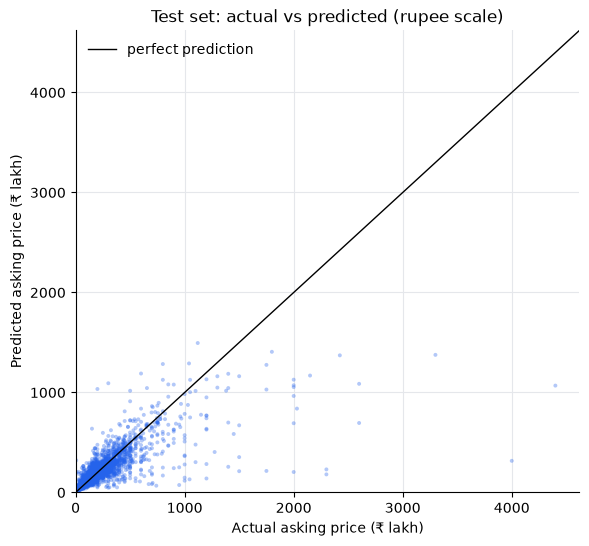

In [18]:
POINT_COLOUR = "#2563eb"   # one series per chart, as in notebooks 19-20
GRID_COLOUR = "#e5e7eb"
errors["log10 residual"] = np.log10(errors["prediction / price"])


def style(ax):
    ax.grid(True, which="major", color=GRID_COLOUR, linewidth=0.8)
    ax.set_axisbelow(True)   # grid lines behind the data
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)


fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(errors["price"] / 1e5, errors["prediction"] / 1e5, s=8, alpha=0.35, color=POINT_COLOUR,
           edgecolors="none")
limit = errors[["price", "prediction"]].max().max() / 1e5 * 1.05
ax.plot([0, limit], [0, limit], color="black", linewidth=1, label="perfect prediction")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel("Actual asking price (₹ lakh)")
ax.set_ylabel("Predicted asking price (₹ lakh)")
ax.set_title("Test set: actual vs predicted (rupee scale)")
ax.legend(loc="upper left", frameon=False)
style(ax)
plt.show()

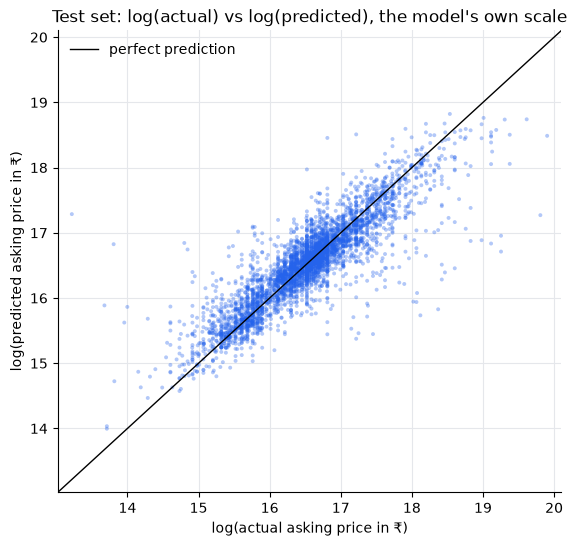

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(np.log(errors["price"]), np.log(errors["prediction"]), s=8, alpha=0.35, color=POINT_COLOUR,
           edgecolors="none")
low = np.log(min(errors["price"].min(), errors["prediction"].min())) - 0.2
high = np.log(max(errors["price"].max(), errors["prediction"].max())) + 0.2
ax.plot([low, high], [low, high], color="black", linewidth=1, label="perfect prediction")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xlabel("log(actual asking price in ₹)")
ax.set_ylabel("log(predicted asking price in ₹)")
ax.set_title("Test set: log(actual) vs log(predicted), the model's own scale")
ax.legend(loc="upper left", frameon=False)
style(ax)
plt.show()

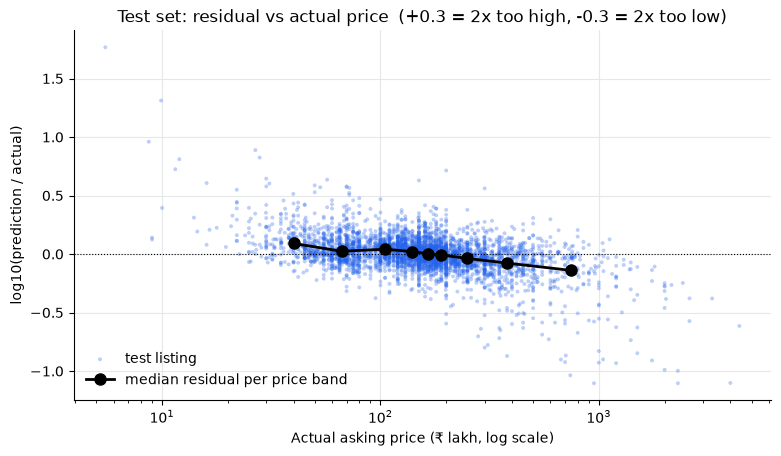

In [20]:
# Residual vs actual price, with the median residual inside each price band
band_medians = errors.groupby("price_band").agg(price=("price", "median"), residual=("log10 residual", "median"))
band_medians = band_medians.reindex(RANGE_NAMES)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(errors["price"] / 1e5, errors["log10 residual"], s=8, alpha=0.3, color=POINT_COLOUR, edgecolors="none",
           label="test listing")
ax.plot(band_medians["price"] / 1e5, band_medians["residual"], color="black", linewidth=2, marker="o", markersize=8,
        label="median residual per price band")
ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xscale("log")
ax.set_xlabel("Actual asking price (₹ lakh, log scale)")
ax.set_ylabel("log10(prediction / actual)")
ax.set_title("Test set: residual vs actual price  (+0.3 = 2x too high, -0.3 = 2x too low)")
ax.legend(loc="lower left", frameon=False)
style(ax)
plt.show()

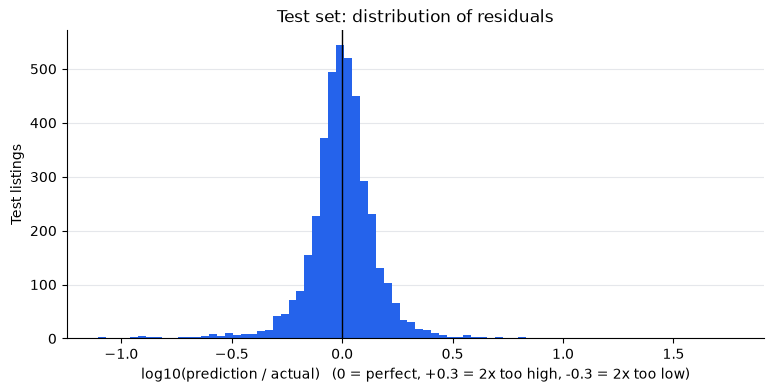

Median residual: +0.001  (= prediction 1.003 x actual)
Mean residual:   -0.001
Middle 50% of residuals: -0.070 to +0.076
Residuals beyond +/-0.3 (2x): 103 too high, 120 too low


In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(errors["log10 residual"], bins=80, color=POINT_COLOUR)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("log10(prediction / actual)   (0 = perfect, +0.3 = 2x too high, -0.3 = 2x too low)")
ax.set_ylabel("Test listings")
ax.set_title("Test set: distribution of residuals")
style(ax)
ax.grid(False, axis="x")
plt.show()

residual = errors["log10 residual"]
print(f"Median residual: {residual.median():+.3f}  (= prediction {10 ** residual.median():.3f} x actual)")
print(f"Mean residual:   {residual.mean():+.3f}")
print(f"Middle 50% of residuals: {residual.quantile(0.25):+.3f} to {residual.quantile(0.75):+.3f}")
print(f"Residuals beyond +/-0.3 (2x): {(residual > np.log10(2)).sum()} too high, {(residual < -np.log10(2)).sum()} too low")

In [22]:
# Is the pull toward the middle visible in the model's predictions? Spread of actual vs predicted log prices
print("Standard deviation of log10 prices, test set:")
print(f"  actual:    {np.log10(errors['price']).std():.3f}")
print(f"  predicted: {np.log10(errors['prediction']).std():.3f}")
print("Price range (₹ lakh):")
print(f"  actual:    {errors['price'].min() / 1e5:.1f} to {errors['price'].max() / 1e5:.1f}")
print(f"  predicted: {errors['prediction'].min() / 1e5:.1f} to {errors['prediction'].max() / 1e5:.1f}")

Standard deviation of log10 prices, test set:
  actual:    0.333
  predicted: 0.292
Price range (₹ lakh):
  actual:    5.5 to 4400.0
  predicted: 12.0 to 1494.7


**Observations (residuals):**

- **No overall bias:** the median residual is +0.001 on the log10 scale (median prediction = 1.003 × actual), and the
  mean residual is −0.001.
- **Typical spread:** half of the listings are predicted between 0.85× and 1.19× their asking price (log10 residual −0.070
  to +0.076).
- The residual distribution is **symmetric around 0 with long tails on both sides**: 103 listings are predicted more than
  2× too high and 120 more than 2× too low.
- **Residual vs price** shows the pull toward the middle as a steady slope. The median residual per price band falls from
  about +0.09 (₹0–50 L) to about −0.14 (₹5 Cr+).
- The **predictions are compressed**:
  - the standard deviation of log10 predictions is 0.292, against 0.333 for the actual prices;
  - predictions span ₹12 lakh–₹14.9 Cr, while actual prices span ₹5.5 lakh–₹44 Cr.
- **Rupee scale:** almost every listing above ₹10 Cr lies below the diagonal.
- **Log scale:** the cloud follows the diagonal closely in the middle and flattens at both ends.

## 9. Locality and geographic information

**Locality status** uses the training set, as the model did. **Geographic information:** listings without a usable
locality centre have no real distances. The pipeline filled them with the **training median** distance, a fallback that is
not a real place (notebook 22).

In [23]:
group_table("locality status", ["frequent locality (10+ in training)", "rare locality (1-9 in training)",
                                "unseen locality", "unknown locality"])

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%)
locality status,,,,,,,
frequent locality (10+ in training),2795,68.5,53.2,15.0,0.3,70.6,64.0
rare locality (1-9 in training),839,20.6,56.3,20.4,0.6,60.2,20.3
unseen locality,175,4.3,82.5,22.3,-4.9,54.3,6.2
unknown locality,272,6.7,81.6,22.6,3.2,54.0,9.5


In [24]:
group_table("centre", ["has centre (distances)", "no centre (distances imputed)"])

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%)
centre,,,,,,,
has centre (distances),3790,92.9,55.4,16.4,0.2,67.6,90.2
no centre (distances imputed),291,7.1,78.5,21.8,3.3,55.0,9.8


In [25]:
errors["family and locality"] = errors["type_family"] + " | " + errors["locality status"]
order = [family + " | " + status for family in ["apartment-like", "house / villa"]
         for status in ["frequent locality (10+ in training)", "rare locality (1-9 in training)", "unseen locality",
                        "unknown locality"]]
group_table("family and locality", order)

,listings,share of listings (%),MAE (₹ lakh),Median APE (%),median signed % error,within ±25% (%),share of total abs error (%)
family and locality,,,,,,,
apartment-like | frequent locality (10+ in training),1883,46.1,28.6,12.6,0.2,79.3,23.1
apartment-like | rare locality (1-9 in training),383,9.4,25.6,14.7,-1.1,72.8,4.2
apartment-like | unseen locality,65,1.6,46.0,16.4,-4.9,69.2,1.3
apartment-like | unknown locality,154,3.8,45.0,21.0,3.2,57.8,3.0
house / villa | frequent locality (10+ in training),912,22.3,104.2,23.5,0.8,52.6,40.8
house / villa | rare locality (1-9 in training),456,11.2,82.0,25.2,2.9,49.6,16.1
house / villa | unseen locality,110,2.7,104.1,29.4,-4.6,45.5,4.9
house / villa | unknown locality,118,2.9,129.5,25.4,3.3,49.2,6.6


**Observations (locality and geographic information):**

| Locality status (vs training) | Listings | Median APE | Median signed |
|---|---|---|---|
| frequent (10+ training listings) | 2,795 | 15.0% | +0.3% |
| rare (1–9) | 839 | 20.4% | +0.6% |
| unseen (0) | 175 | 22.3% | −4.9% |
| unknown locality | 272 | 22.6% | +3.2% |

- Errors grow as the model knows less about the location. Apartments in frequent localities are the best-predicted
  group in the whole analysis (Median APE 12.6%, 79% within ±25%).
- Listings **without a usable locality centre** (291; their distances are the training median, a fallback that is not a
  real place) have a Median APE of 21.8%, against 16.4% for listings with real distances.
- The worst combination is **houses/villas with an unknown locality** (MAE ₹130 lakh, Median APE 25.4%).

## 10. The known failure modes from notebooks 19–26

Each row is one failure mode seen during cross-validation, now measured on the test set. These are **observations**;
none of them leads to a change of the model.

"Suspicious-looking extreme asking prices" uses only definitions that already exist in the project:

- a price below ₹10 lakh (the "Price < ₹10 L" column of `docs/outlier_handling.md`, B1);
- a listing whose price could not be checked by R1 because its area is missing (notebook 20, section 8).

In [26]:
def failure_row(label, mask, note):
    part = errors[mask]
    return {
        "failure mode": label,
        "listings": len(part),
        "MAE (₹ lakh)": part["abs error"].mean() / 1e5,
        "Median APE (%)": part["abs % error"].median(),
        "median signed % error": part["signed % error"].median(),
        "error ≥ 2x (%)": ((part["prediction / price"] >= 2) | (part["prediction / price"] <= 0.5)).mean() * 100,
        "share of total abs error (%)": part["abs error"].sum() / errors["abs error"].sum() * 100,
        "what the CV had shown": note,
    }


failure_modes = pd.DataFrame([
    failure_row("all test listings", pd.Series(True, index=errors.index), "CV Median APE 16.5%"),
    failure_row("cheapest: ₹0-50 L", errors["price_band"] == "0-50 L", "over-predicted, median +24% (nb 25)"),
    failure_row("expensive: ₹5 Cr+", errors["price"] >= 5e7, "under-predicted, median -26% (nb 25)"),
    failure_row("luxury: ₹20 Cr+", errors["price"] >= 20e7, "under-predicted, median -62% (nb 25)"),
    failure_row("houses / villas", errors["type_family"] == "house / villa", "Median APE 23.6% vs 13.4% apartments"),
    failure_row("area missing (any reason)", errors["area status"] != "area known", "among the largest errors (nb 19-20)"),
    failure_row("price below ₹10 L", errors["price"] < 10e5, "probable entry errors (nb 20, outlier doc B1)"),
    failure_row("price below ₹50 L and area missing", (errors["price"] < 50e5) & (errors["area status"] != "area known"),
                "price not checkable by R1 (nb 20)"),
]).set_index("failure mode")
failure_modes.round(1)

,listings,MAE (₹ lakh),Median APE (%),median signed % error,error ≥ 2x (%),share of total abs error (%),what the CV had shown
failure mode,,,,,,,
all test listings,4081,57.0,16.8,0.3,5.5,100.0,CV Median APE 16.5%
cheapest: ₹0-50 L,311,18.9,24.9,23.2,14.8,2.5,"over-predicted, median +24% (nb 25)"
expensive: ₹5 Cr+,256,354.6,30.3,-26.6,22.7,39.0,"under-predicted, median -26% (nb 25)"
luxury: ₹20 Cr+,16,1665.6,58.5,-58.5,68.8,11.5,"under-predicted, median -62% (nb 25)"
houses / villas,1596,99.7,24.6,1.0,9.7,68.4,Median APE 23.6% vs 13.4% apartments
area missing (any reason),348,115.6,26.6,5.7,15.5,17.3,among the largest errors (nb 19-20)
price below ₹10 L,5,117.2,811.9,811.9,60.0,0.3,"probable entry errors (nb 20, outlier doc B1)"
price below ₹50 L and area missing,46,39.9,63.7,63.7,30.4,0.8,price not checkable by R1 (nb 20)


In [27]:
print("Test listings priced below ₹10 lakh (outlier doc B1 reporting level):")
listing_view(errors[errors["price"] < 10e5].sort_values("price"))

Test listings priced below ₹10 lakh (outlier doc B1 reporting level):


,property_id,property_type,bedrooms,area (sq-ft),area status,locality,locality status,centre,channel,price (₹ lakh),prediction (₹ lakh),prediction / price,rate (₹/sq-ft)
1277,listing_022,Residential House,9,NaN,no area given,Gayatri Nagar Godavari Homes,rare locality (1-9 in training),has centre (distances),Telecalling,5.5,321.67,58.49,NaN
1356,listing_024,Apartment,2,NaN,no area given,Ameenpur Plots,rare locality (1-9 in training),has centre (distances),Web,8.7,79.34,9.12,NaN
886,listing_042,Apartment,1,333.0,area known,Meerpet,frequent locality (10+ in training),has centre (distances),ownerDashboard_wap,9.0,12.44,1.38,2702.7
379,listing_043,Apartment,1,333.0,area known,Meerpet,frequent locality (10+ in training),has centre (distances),ownerDashboard_wap,9.0,11.98,1.33,2702.7
1072,listing_023,Residential House,5,NaN,area set missing by R2,Saroornagar,frequent locality (10+ in training),has centre (distances),NaN,9.9,202.86,20.49,NaN


**Observations (known failure modes, test vs cross-validation):**

- **Cheapest listings over-predicted:** confirmed. ₹0–50 L median +23% (CV +24%); 15% of them are off by 2× or more.
- **Expensive listings under-predicted:** confirmed. ₹5 Cr+ median −27% (CV −26%).
- **₹20 Cr+ homes:** confirmed. Median −58.5% (CV −62%), and all 16 are too low.
- **Houses/villas:** confirmed. Median APE 24.6% vs 13.4% for apartment-like types (CV 23.6% vs 13.4%).
- **Missing area:** confirmed. Median APE 26.6% vs 16.3% with a known area.
- **Suspicious-looking extreme asking prices:**
  - 5 test listings are priced below ₹10 lakh. Two are 333 sq-ft flats at ₹9 lakh, predicted at ₹12 lakh: plausible
    small flats, and reasonable predictions.
  - The other three have no usable area and are predicted **9–58×** higher (₹0.8–3.2 Cr). They resemble the probable
    entry errors of notebook 20 and `docs/outlier_handling.md` B1, but no existing rule can check them, because they have
    no area.
  - More broadly, the 46 test listings priced below ₹50 lakh **and** without a usable area are over-predicted by a median
    of 64%.
- The test set has **no listing at ₹2 lakh or less**, unlike the training set (5 such listings, notebook 20).

**Every failure mode seen in cross-validation reappears on the test set with a similar size.** None of these
observations is used to change the model, the features, the thresholds or the data.

## 11. Checks

In [28]:
# The frozen model and data were used unchanged
assert len(train_features) == 16219 and len(test_features) == 4081
assert set(train["property_group_id"]).isdisjoint(test["property_group_id"])
fitted_hgb = final_model.named_steps["model"].regressor_
FROZEN = {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31, "max_depth": None, "min_samples_leaf": 40,
          "l2_regularization": 1.0, "early_stopping": False, "random_state": 42}
for key, value in FROZEN.items():
    assert fitted_hgb.get_params()[key] == value, key
assert fitted_hgb.n_iter_ == 200
print("1. Same split (16,219 / 4,081, no shared property group) and the frozen HGB settings of notebook 25.")

# The imputer learned from training rows only (as in notebook 26)
imputer = final_model.named_steps["preprocess"].named_transformers_["numeric"].named_steps["impute"]
assert np.allclose(imputer.statistics_, train_features[NUMERIC_FEATURES].median().values)
print("2. Preprocessing learned from the training set only.")

# Predictions reproduce notebook 26, every test listing once
assert errors.index.equals(test.index) and errors["property_id"].is_unique and len(errors) == 4081
print("3. Test metrics reproduce notebook 26; one prediction per test listing; no listing removed.")

# Source files unchanged, nothing saved
for path, md5 in EXPECTED_MD5.items():
    assert file_md5(path) == md5, f"{path.name} changed!"
print("4. cleaned_listings.csv, train_test_split.csv, localities.csv and build_features.py are unchanged.")
print("5. No model, prediction file or transformed dataset was saved.")

1. Same split (16,219 / 4,081, no shared property group) and the frozen HGB settings of notebook 25.

2. Preprocessing learned from the training set only.
3. Test metrics reproduce notebook 26; one prediction per test listing; no listing removed.
4. cleaned_listings.csv, train_test_split.csv, localities.csv and build_features.py are unchanged.
5. No model, prediction file or transformed dataset was saved.


## 12. Final conclusions

### What the model predicts reasonably well

- **Apartments**, especially in localities with at least 10 training listings: Median APE 12.6–13.2%, about 78–79% within
  ±25%, and no systematic bias.
- **The middle of the collected price range (about ₹50 L–3 Cr):** Median APE 12–17% in every price band.
- **The typical listing overall:** median prediction ≈ actual (no global bias); half of all listings are within about −15%
  to +19% of their asking price.

### Where it performs poorly

- **₹20 Cr+ homes:** all under-predicted, median −58%. The model never predicts above ₹15 Cr.
- **₹5 Cr+ homes in general:** median −27%. They are 6% of listings but 39% of the rupee error.
- **Houses and villas:** about twice the relative error of apartments (24.6% vs 13.4%). They cause 68% of the rupee
  error, even when their area is known.
- **Listings without a usable area**, especially villas without any area (Median APE 41%).
- **Unknown or unseen localities:** Median APE 22–23%.
- **Very cheap listings with implausible-looking prices**, predicted many times too high.

### Systematic biases

- **Regression toward the middle:**
  - cheap listings are predicted too high (+23% below ₹50 L);
  - expensive listings too low (−16% in ₹3–5 Cr, −27% above ₹5 Cr);
  - the predictions are narrower than the actual prices.
- **Rupee metrics are dominated by a few expensive homes;** percentage metrics describe the typical listing. Both are
  needed to describe this model.

### Limitations caused by the dataset

- **The target is an advertised asking price** (91% owner listings), including optimistic and mistyped prices. Some
  extreme prices look like entry errors but cannot be proven wrong; R1 cannot check listings without a usable area.
- **The data is one scraped snapshot collected by price-range searches** with ~3,000-result caps
  (`docs/sampling_process.md`). Price bands, property types and localities are not represented in proportion to the
  market.
- **Very few luxury listings:** 48 training listings at ₹20 Cr+. That is too few to learn that range.
- **Area can mean plot or built-up area for houses/villas,** and some areas are probably in the wrong unit; R2 turns the
  clearest cases into missing values.
- **About 7% of listings have no usable locality,** and their distances are a fallback value.

### What cannot be concluded from this dataset

- Anything about **sale prices, transaction prices or market value**. The model predicts **asking** prices.
- That these errors describe **the Hyderabad housing market**. They describe this collection of listings only.
- How the model would perform **at another time**, on another website or after market changes. There is one snapshot
  and no time-series evaluation.
- Whether the largest over- and under-predictions are **model failures or data errors**. For the implausible-looking
  prices, the data cannot tell.
- **Why** the model errs for a given group. The explanations above (plot vs built-up area, too few luxury homes,
  fallback locations) are consistent with the evidence, but they are not tested causes.
- Market shares or price levels by locality, property type or price band.